# Supplementary Fig. S12: Behavior-derived value predicts neural activity under different learning rate parameters in vLPFC

[AI generated summary] Same analysis and plotting code as Fig. 4g (`fig4g_learning_rate.ipynb`), for the vLPFC sessions with significant value coding. The foraging value is computed with different learning rates (α = 0.1 to 0.9, blue to red) and decoded from the population activity (ridge regression, 10-fold cross-validation). Left: decoding performance (R²) over the trial for each α; shaded area: task engagement period. Right: mean R² over the task engagement period as a function of α. Dashed line: learning rate fitted to the behavior.

**How to run:** set `DATA_PATH` in `popy/config.py` (uses `behavior/recordings_summary.csv`), then run all cells. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/population_decoding/multiple_alphas_ridge` (see the README). To recompute them, run in this folder: `python ../fig3/run_decoding.py multiple_alphas_ridge` (several hours on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import xarray as xr

from popy.plotting.plotting_tools import plot_keypoints
from popy.config import COLORS

from helpers import load_decoding_res_new, add_if_signif, remove_irrelevant_sessions, add_subareas

# set fontsize to 8
plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Load results

In [3]:
res_alphas_original = load_decoding_res_new(folder='multiple_alphas_ridge')
res_alphas_original = add_if_signif(res_alphas_original, plim=.05, N_consecutives=4)
res_alphas_original = remove_irrelevant_sessions(res_alphas_original)  # remove sessions that are not significant enough
res_alphas_original = add_subareas(res_alphas_original)  # add subareas to the results
res_alphas_original

kept: 66 / 230


<xarray.Dataset>
Dimensions:         (target: 19, session: 115, time: 75, area: 2)
Coordinates:
  * target          (target) <U15 'stay_value_0.05' ... 'stay_value_0.95'
  * area            (area) object 'LPFC' 'MCC'
  * time            (time) float64 0.0 0.1 0.2 0.3 0.4 ... 7.0 7.1 7.2 7.3 7.4
  * session         (session) object 'ka_230520' 'ka_090720' ... 'po_200722'
    monkey          (session) object 'ka' 'ka' 'ka' 'ka' ... 'po' 'po' 'po' 'po'
    lpfc_subregion  (session) <U5 'dLPFC' 'dLPFC' 'dLPFC' ... 'dLPFC' 'dLPFC'
Data variables:
    scores          (target, session, time, area) float64 nan nan ... -0.05522
    pvals           (target, session, time, area) float64 nan nan ... nan 0.1238
    perm_mean       (target, session, time, area) float64 nan nan ... -0.09404
    perm_std        (target, session, time, area) float64 nan nan ... 0.03253
    if_significant  (target, session, time, area) bool True True ... True False

---
# Supplementary Fig. S12

ka - vLPFC: 7 / 12 sessions (5 NaN)
po - vLPFC: 3 / 7 sessions (4 NaN)


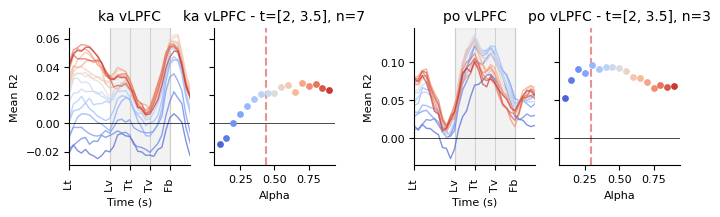

In [4]:
import matplotlib.gridspec as gridspec

cut_percentile = 0.01  # we remove extreme outliers to get interpretable results
eval_window = [2, 3.5]  # this is the time window under which we average the decoder performances for the second plot

x_lim=(1, 4)  # time window to show

paper_format = True
show_datapoints = False  # whether to show individual data points or not

monkeys = np.unique(res_alphas_original.monkey.values)
areas = ['vLPFC']  # Supplementary Fig. S12: vLPFC only
targets = res_alphas_original.target.values
alphas = [float(target.split("_")[-1]) for target in targets]

# color gradient red to green
colors = plt.cm.coolwarm(np.linspace(0, 1, len(targets)))
from popy.config import MODEL_PARAMS
alpha_monkey = {'ka': MODEL_PARAMS['ka']['alpha'], 'po': MODEL_PARAMS['po']['alpha']}

# plot size in cm
if paper_format:
    w = 20
    h = 4.5
    s = 15
    lw = 1
else:
    w = 36
    h = 18
    s = 40
    lw = 1.5

# Create figure
fig = plt.figure(figsize=(w/2.54, h/2.54))

# Create a master grid: 1 row (area) × 2 columns (monkeys)
outer_grid = gridspec.GridSpec(1, 2, figure=fig, hspace=.5, wspace=0.3)

# Iterate through each monkey-area combination
for m, monkey_temp in enumerate(monkeys):
    for a, area_temp in enumerate(areas):
        
        # Create inner grid for this (monkey, area) pair: 1 row × 2 columns with NO gap
        inner_grid = gridspec.GridSpecFromSubplotSpec(1, 2, outer_grid[a, m], 
                                                     wspace=0.2, hspace=0)
        
        # Create subplots - time series first, then alpha with shared y-axis
        ax_time = fig.add_subplot(inner_grid[0, 0])   # Time series subplot
        ax_alpha = fig.add_subplot(inner_grid[0, 1], sharey=ax_time)  # Alpha subplot with shared y
        ax_alpha.tick_params(labelleft=False)

        for i, target_temp in enumerate(targets):
            if i == 0 or i == len(targets)-1:
                continue
            
            res_alphas_temp = res_alphas_original.sel(target=target_temp, session=res_alphas_original.monkey == monkey_temp)

            scores_temp = res_alphas_temp.scores
            scores_temp = scores_temp.where(scores_temp > scores_temp.quantile(cut_percentile), np.nan)  # remove outliers
            
            if area_temp == 'MCC':
                scores_all = scores_temp.sel(area=area_temp)
                scores_in_time = scores_all.mean('session')
                scores_at_time = scores_all.sel(time=slice(*eval_window)).mean('time')      
            else:
                scores_all = scores_temp.sel(area='LPFC', session=scores_temp.lpfc_subregion == area_temp)
                scores_in_time = scores_all.mean('session')
                scores_at_time = scores_all.sel(time=slice(*eval_window)).mean('time')

            # Plot time series
            scores_in_time_smooth = np.convolve(scores_in_time, np.ones(5)/5, mode='same')
            ax_time.plot(res_alphas_temp.time, scores_in_time_smooth, color=colors[i], alpha=.7, linewidth=lw)

            # Plot alpha scatter
            ax_alpha.scatter(
                alphas[i],
                scores_at_time.mean(),
                color=colors[i],
                s=s,
                alpha=1,
                zorder=10
            )

            # Add individual data points with jitter
            if show_datapoints:
                x_jittered = alphas[i] + np.random.normal(0, 0.005, len(scores_at_time))
                ax_alpha.scatter(
                    x_jittered,
                    scores_at_time,
                    color='black',
                    s=s/5,
                    alpha=0.5
                )

        # add grey shadow in the background for the time of interest
        ax_time.axvspan(eval_window[0], eval_window[1], color='grey', alpha=0.1, label='Eval Window')

        n_sessions = len(scores_all)
        n_sessions_nonnan = np.count_nonzero(~np.isnan((scores_all.mean('time'))))
        n_sessions_nan = np.count_nonzero(np.isnan((scores_all.mean('time'))))
        print(f'{monkey_temp} - {area_temp}: {n_sessions_nonnan} / {n_sessions} sessions ({n_sessions_nan} NaN)')
         
        # Set titles only on top row
        ax_time.set_title(f'{monkey_temp} {area_temp}', fontsize=10)
        ax_alpha.set_title(f'{monkey_temp} {area_temp} - t={eval_window}, n={n_sessions_nonnan}', fontsize=10)

        # Add vertical line for monkey-specific alpha
        ax_alpha.axvline(alpha_monkey[monkey_temp], color='tab:red', linestyle='--', alpha=.5)

        # Set properties for time series plot
        plot_keypoints(ax_time, n_extra_trials=(0, 0), fontsize=8, xlabels='short')
        ax_time.grid(axis='x', alpha=.5)
        ax_time.set_xlim(x_lim)
        
        # Manually adjust y-axis limits based on visible data within x_lim
        y_values = []
        for line in ax_time.get_lines():
            x_data = line.get_xdata()
            y_data = line.get_ydata()
            # Find y values within the x_lim range
            mask = (x_data >= x_lim[0]) & (x_data <= x_lim[1])
            if np.any(mask):
                y_values.extend(y_data[mask])
        
        if y_values:
            y_min, y_max = np.nanmin(y_values), np.nanmax(y_values)
            y_range = y_max - y_min
            margin = y_range * 0.05  # Add 5% margin
            ax_time.set_ylim(y_min - margin, y_max + margin)
        
        # Set x-labels only on bottom row
        if a == len(areas) - 1:
            ax_time.set_xlabel('Time (s)')
            ax_alpha.set_xlabel('Alpha')
        
        # Set y-labels only on leftmost subplots
        if a == 0:
            ax_time.set_ylabel('Mean R2')
        else:
            # Remove y-axis labels and ticks for non-leftmost time plots
            #ax_time.set_ylabel('')
            #ax_time.tick_params(left=False, labelleft=False)
            ...
        
        # Remove spines
        ax_time.spines['top'].set_visible(False)
        ax_time.spines['right'].set_visible(False)
        ax_alpha.spines['top'].set_visible(False)
        ax_alpha.spines['right'].set_visible(False)
        

        ax_alpha.axhline(0, color='black', linewidth=.5)
        ax_time.axhline(0, color='black', linewidth=.5)

if paper_format:
    plt.tight_layout()

fig.savefig(os.path.join(FIGS_PATH, 'figS12_learning_rate_vlpfc.svg'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [5]:
# Export source data (Supplementary Figure 12)
import pandas as pd
from popy.source_data import export_source_data

# vLPFC: same sessions, outlier removal, averaging and smoothing as in the plot above
t_vec = res_alphas_original.time.values
in_view = (t_vec >= x_lim[0] - 1e-6) & (t_vec <= x_lim[1] + 1e-6)  # displayed time window
alphas_sd = [alphas[i] for i in range(1, len(targets) - 1)]  # the first and last learning rates are not plotted
tables_s12 = {}
right_s12 = pd.DataFrame({'Learning rate alpha': alphas_sd})
ref_s12 = []
for monkey_sd in monkeys:
    left_sd = pd.DataFrame({'Time (s)': t_vec[in_view]})
    means_sd, n_sd = [], []
    for i, target_sd in enumerate(targets):
        if i == 0 or i == len(targets) - 1:
            continue
        res_sd = res_alphas_original.sel(target=target_sd, session=res_alphas_original.monkey == monkey_sd)
        scores_sd = res_sd.scores
        scores_sd = scores_sd.where(scores_sd > scores_sd.quantile(cut_percentile), np.nan)  # remove outliers
        scores_sd = scores_sd.sel(area='LPFC', session=scores_sd.lpfc_subregion == 'vLPFC')
        left_sd[f'R2, alpha = {alphas[i]:.2f}'] = np.convolve(scores_sd.mean('session'), np.ones(5)/5, mode='same')[in_view]
        scores_window_sd = scores_sd.sel(time=slice(*eval_window)).mean('time')  # one value per session
        means_sd.append(float(scores_window_sd.mean()))
        n_sd.append(int(np.count_nonzero(~np.isnan(scores_window_sd))))
    tables_s12[f'Left: monkey {monkey_sd.upper()}, vLPFC, value prediction (R2) over time, one column per learning rate'] = left_sd
    right_s12[f'Monkey {monkey_sd.upper()}, vLPFC, mean R2 (dot)'] = means_sd
    right_s12[f'Monkey {monkey_sd.upper()}, vLPFC, n sessions'] = n_sd
    ref_s12.append({'Monkey': monkey_sd.upper(), 'Learning rate alpha fitted to behavior (dashed line)': alpha_monkey[monkey_sd]})
tables_s12[f'Right: mean R2 during the task engagement period ({eval_window[0]}-{eval_window[1]} s) vs. learning rate'] = right_s12
tables_s12['Dashed line'] = pd.DataFrame(ref_s12)

n_sessions_sd = ', '.join(f'{m.upper()}: n = {max(right_s12[f"Monkey {m.upper()}, vLPFC, n sessions"])}' for m in monkeys)
export_source_data(
    'Supplementary Figure 12',
    tables_s12,
    'Prediction of the behavioral (foraging model) value from the vLPFC population activity: cross-validated R2 of a ridge regression '
    'decoder (10-fold cross-validation) of the value computed with learning rates alpha from 0.1 to 0.9 (colors blue to red), in the '
    f'sessions with significant value coding ({n_sessions_sd} sessions). R2 values below the 1st percentile (per monkey and learning '
    'rate) are removed as outliers. Left: mean across sessions over time, moving average over 5 time bins (0.5 s), displayed window '
    f'{x_lim[0]}-{x_lim[1]} s of the time-normalized trial (Lv = 2 s, Tt = 2.5 s, Fb = 3.5 s; shaded area: task engagement period, '
    f'{eval_window[0]}-{eval_window[1]} s). Right: mean across sessions of the R2 averaged over the task engagement period. Dashed '
    'line: learning rate of the foraging model fitted to the behavior. No error bars.')

Supplementary Figure 12: source data saved (31 rows, 31 rows, 17 rows, 2 rows)
